# Figures

Regenerates the paper's descriptive and inferential figures from the exported result
CSVs: the input-retention and performance-vs-benchmark descriptive figures, the
random-vs-crossover and random-vs-daily seed-paired comparisons, and the
schedule-component heatmap. `descriptive_figures.py` is the shared plotting
implementation; see `docs/METHODS_AND_EVIDENCE.md` for the figure-to-export mapping.

In [1]:
%matplotlib inline
import os, sys, pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from stable_baselines3 import A2C, PPO, SAC
from finrl.meta.env_stock_trading.env_stocktrading import StockTradingEnv
sys.path.insert(0, str(Path(os.getcwd())))
from utils.config import SEEDS, WINDOWS
from utils.common import (
    make_window_data, get_indicators, make_env_kwargs,
    run_prediction_vecnorm, bootstrap_ci, compare_placebo,
)
from utils.tables import compute_metrics

In [2]:
FINRL_PATH = Path(os.environ['FINRL_PATH'])
MODELS_DIR = FINRL_PATH / 'models' / 'dow' / 'experiment_1'

#DATASETS = ["all",'mv', "mv2", 'mvx', 'mvx2', 'flt_mvx2', 'flt_mvx', 'flt_mvx_trg', 'flt_mvx2_trg','bollx', 'flt_bollx', 'flt_bollrsix1', 'flt_bollrsix2', 'bollmvx2','flt_bollmvx2']

DATASETS = [ "all","mv2", "mvx2","flt_mvx2", "flt_mvx2", "mvx2_trg",  "flt_mvx2_trg", 
    "boll", "bollx", "flt_bollx", "bollx_trg", "flt_bollx_trg" 
] 
ALGOS = {'a2c': A2C, 'ppo': PPO, 'sac': SAC}
WINDOWS_TO_RUN = ['w1', 'w4', 'w3']
DEVICE = 'cpu'
CACHE_DIR = FINRL_PATH / 'results' / 'dow' / 'experiment_1'
BACKTEST_CACHE = CACHE_DIR / 'backtest_cache.pkl'
PLACEBO_CACHE = CACHE_DIR / "backtest_cache_mv2boll.pkl"
print(f'Models: {MODELS_DIR}')
print(f'Cache: {PLACEBO_CACHE}')

Models: /home/main/Programming/finrl/models/dow/experiment_1
Cache: /home/main/Programming/finrl/results/dow/experiment_1/backtest_cache_mv2boll.pkl


In [3]:
# Load existing backtest cache
with open(BACKTEST_CACHE, 'rb') as f:
    cache = pickle.load(f)
results = cache['results']

# Rebuild agg from cached results
def aggregate_seeds(results):
    agg = {}
    for window, ds_dict in results.items():
        agg[window] = {}
        for ds, algo_dict in ds_dict.items():
            agg[window][ds] = {}
            for algo, seed_list in algo_dict.items():
                if not seed_list:
                    continue
                mat = pd.concat(seed_list, axis=1)
                agg[window][ds][algo] = {
                    'mean': mat.mean(axis=1),
                    'std': mat.std(axis=1),
                    'n': len(seed_list),
                }
    return agg

agg = aggregate_seeds(results)
print(f'✓ Loaded agg: {len(agg)} windows')

# Reload data (test splits only)
data = make_window_data(DATASETS, windows=WINDOWS_TO_RUN, cvtd=False, splits=['train','test'])
print(f'✓ Loaded data: {len(data)} windows')

✓ Loaded agg: 3 windows
✓ Loaded data: 3 windows


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from matplotlib.lines import Line2D

# Load consolidated metrics
metrics_path = Path('/home/main/Dropbox/phd/ResearchFinRL/FinRLCode/myresearch/tables_mv2boll/metrics_table.csv')
metrics_df = pd.read_csv(metrics_path)

# Helper: extract best-performing non-benchmark configuration for each window/algo
def get_best_variant(metrics_df, window, algo, exclude_baselines=['all', '[DJIA]', '[MVO]']):
    """Get best non-benchmark configuration by Return% for a window/algo pair."""
    subset = metrics_df[(metrics_df['window'] == window) & (metrics_df['algo'] == algo)]
    # Exclude baselines
    subset = subset[~subset['dataset'].isin(exclude_baselines)]
    if len(subset) == 0:
        return None
    best_idx = subset['Return%'].idxmax()
    return subset.loc[best_idx]

# Helper: get baseline ("all" = daily benchmark)
def get_baseline(metrics_df, window, algo):
    """Get the 'all' (daily benchmark) result for a window/algo pair."""
    subset = metrics_df[(metrics_df['window'] == window) & (metrics_df['algo'] == algo) & (metrics_df['dataset'] == 'all')]
    if len(subset) == 0:
        return None
    return subset.iloc[0]

print("✓ Data loaded and helper functions defined")

✓ Data loaded and helper functions defined


In [9]:
# ============================================================================
# TABLE: Mean ± Std Return% per representation category × window × algo
# (6 categories: correctly separates continuous-only from hybrid and binary-trigger)
# ============================================================================

# Continuous-only datasets (no binary trigger flags)
_CONTINUOUS_ALT = {'mv', 'mv2', 'boll'}
# Full-daily binary-trigger datasets (not subsampled, only binary flags)
_FD_BINTRIG = {'mvx_trg', 'mvx2_trg', 'bollx_trg'}

def _is_hybrid_full(ds):
    """Full-daily datasets that mix continuous indicators + binary trigger flags."""
    return (
        not ds.startswith('flt_') and
        not ds.endswith('_trg') and
        ds not in {'all', '[DJIA]', '[MVO]'} and
        ds not in _CONTINUOUS_ALT
    )

REPR_CATS = {
    'Continuous RL Baseline':       lambda df, a: df[(df['algo']==a) & (df['dataset']=='all')],
    'Full daily Continuous (alt.)':  lambda df, a: df[(df['algo']==a) & (df['dataset'].isin(_CONTINUOUS_ALT))],
    'Full daily Hybrid':            lambda df, a: df[(df['algo']==a) & df['dataset'].apply(_is_hybrid_full)],
    'Full daily Binary-Trigger':    lambda df, a: df[(df['algo']==a) & (df['dataset'].isin(_FD_BINTRIG))],
    'Subsampled Hybrid':            lambda df, a: df[(df['algo']==a) & df['dataset'].str.startswith('flt_') & ~df['dataset'].str.endswith('_trg')],
    'Subsampled Binary-Trigger':    lambda df, a: df[(df['algo']==a) & df['dataset'].str.startswith('flt_') & df['dataset'].str.endswith('_trg')],
}

rows = []
for window in ['w1', 'w2', 'w3']:
    df_w = metrics_df[metrics_df['window'] == window]
    for algo in ['a2c', 'ppo', 'sac']:
        for rep_name, selector in REPR_CATS.items():
            df_cat = selector(df_w, algo)
            rows.append({
                'Window':         window.upper(),
                'Algo':           algo.upper(),
                'Representation': rep_name,
                'N':              len(df_cat),
                'Mean Return%':   round(df_cat['Return%'].mean(), 2) if len(df_cat) > 0 else float('nan'),
                'Std Return%':    round(df_cat['Return%'].std(),  2) if len(df_cat) > 1 else float('nan'),
            })

detail_df = pd.DataFrame(rows)

# ── Compact pivot: Representation × Window (averaged over algos) ──────────────
compact = (
    detail_df
    .groupby(['Representation', 'Window'])[['Mean Return%', 'Std Return%']]
    .mean()
    .round(2)
    .reset_index()
)
compact['Mean ± Std'] = compact.apply(
    lambda r: f"{r['Mean Return%']:.2f} ± {r['Std Return%']:.2f}", axis=1
)
pivot_compact = compact.pivot(index='Representation', columns='Window', values='Mean ± Std')
pivot_compact = pivot_compact.reindex(list(REPR_CATS.keys()))

print('=== Return%: Mean ± Std per representation × window (averaged over A2C/PPO/SAC) ===')
display(pivot_compact)

# ── Full breakdown: Representation × Window × Algo ───────────────────────────
detail_df['Mean ± Std'] = detail_df.apply(
    lambda r: f"{r['Mean Return%']:.2f} ± {r['Std Return%']:.2f}"
              if not pd.isna(r['Mean Return%']) else '—',
    axis=1
)
pivot_full = detail_df.pivot_table(
    index='Representation', columns=['Window', 'Algo'],
    values='Mean ± Std', aggfunc='first'
)
pivot_full = pivot_full.reindex(list(REPR_CATS.keys()))

print('\n=== Return%: Mean ± Std per representation × window × algo ===')
display(pivot_full)

# ── N counts for verification ─────────────────────────────────────────────────
print('\n=== N (dataset count) per category × window × algo ===')
n_pivot = detail_df.pivot_table(index='Representation', columns=['Window','Algo'], values='N', aggfunc='first')
n_pivot = n_pivot.reindex(list(REPR_CATS.keys()))
display(n_pivot)

# ── Save ──────────────────────────────────────────────────────────────────────
detail_df.to_csv('tables/all/repr_window_summary.csv', index=False)
print('\n✓ Saved: tables/all/repr_window_summary.csv')


=== Return%: Mean ± Std per representation × window (averaged over A2C/PPO/SAC) ===


Window,W1,W2,W3
Representation,,,
Continuous RL Baseline,25.97 ± nan,nan ± nan,16.69 ± nan
Full daily Continuous (alt.),27.52 ± 3.28,nan ± nan,12.53 ± 2.49
Full daily Hybrid,26.31 ± 1.85,nan ± nan,13.74 ± 2.42
Full daily Binary-Trigger,28.88 ± 4.07,nan ± nan,10.87 ± 2.80
Subsampled Hybrid,29.90 ± 1.54,nan ± nan,14.89 ± 1.97
Subsampled Binary-Trigger,28.70 ± 2.00,nan ± nan,16.10 ± 3.24



=== Return%: Mean ± Std per representation × window × algo ===


Window                                  W1                              W2  \
Algo                                   A2C           PPO           SAC A2C   
Representation                                                               
Continuous RL Baseline         26.23 ± nan   33.21 ± nan   18.47 ± nan   —   
Full daily Continuous (alt.)  25.97 ± 2.41  33.11 ± 2.93  23.48 ± 4.50   —   
Full daily Hybrid             25.15 ± 0.52  30.17 ± 1.77  23.62 ± 3.26   —   
Full daily Binary-Trigger     23.33 ± 6.35  33.33 ± 3.80  29.98 ± 2.07   —   
Subsampled Hybrid             33.91 ± 0.34  21.76 ± 0.91  34.03 ± 3.37   —   
Subsampled Binary-Trigger     34.14 ± 2.57  19.00 ± 1.52  32.97 ± 1.92   —   

Window                                          W3                              
Algo                         PPO SAC           A2C           PPO           SAC  
Representation                                                                  
Continuous RL Baseline         —   —   12.42 ± nan   21.19 ± nan   16.47 ± nan  
Full daily Continuous (alt.)   —   —  10.08 ± 2.09  16.66 ± 3.81  10.86 ± 1.56  
Full daily Hybrid              —   —  11.62 ± 1.87  18.85 ± 3.05  10.76 ± 2.35  
Full daily Binary-Trigger      —   —  15.15 ± 1.06  11.70 ± 0.92   5.76 ± 6.43  
Subsampled Hybrid              —   —  13.92 ± 0.99  13.69 ± 4.54  17.05 ± 0.37  
Subsampled Binary-Trigger      —   —  15.58 ± 1.32  20.22 ± 5.73  12.50 ± 2.68


=== N (dataset count) per category × window × algo ===


Window                        W1          W2          W3        
Algo                         A2C PPO SAC A2C PPO SAC A2C PPO SAC
Representation                                                  
Continuous RL Baseline         1   1   1   0   0   0   1   1   1
Full daily Continuous (alt.)   2   2   2   0   0   0   2   2   2
Full daily Hybrid              2   2   2   0   0   0   2   2   2
Full daily Binary-Trigger      2   2   2   0   0   0   2   2   2
Subsampled Hybrid              2   2   2   0   0   0   2   2   2
Subsampled Binary-Trigger      2   2   2   0   0   0   2   2   2


✓ Saved: tables/all/repr_window_summary.csv


## Descriptive scheduling figures (2026-09-07)

Run this section independently of the legacy cells above. It requires `numpy`, `pandas`, and `matplotlib`, but no model caches or FinRL imports. The adjacent `descriptive_figures.py` script is the single plotting implementation.

**Figure 1:** per-seed mean return, Sharpe, signed maximum drawdown and executed trades; bars show crossover minus matched daily performance; Trades avoided reverses the subtraction (daily minus crossover). Blue indicates positive changes, red negative changes. Equal configuration weighting; each row is a different aggregation of the same experiments. Windows are labelled by calendar year. Descriptive means are not continuous-portfolio metrics or significance tests.

**Figure 2:** four bars show total input retention relative to 4,275 daily dates × 361 state entries. Adjacent columns show retained dates and state width as percentages; their fractions multiply to give total retention. Existing window exports have identical full-dataset counts, not separate training-window estimates. The missing filtered Bollinger-crossovers count/dimension is inferred from the shared Bollinger schedule and the 121-entry crossover state. Source CSVs remain unchanged.

PNG previews below are saved from the validated standalone run. PDF/SVG figures, plotted-value CSVs and a provenance manifest are exported alongside them. Rerun the following cells to refresh all outputs.

**Notes for LaTeX captions:** Each row is an alternative aggregation of the same evaluations, with metrics computed per seed before equal configuration weighting. pp denotes percentage points; positive signed-drawdown differences mean less severe drawdowns. Fewer trades does not independently imply better performance. These are descriptive differences, without significance tests or confidence intervals. Figure 2 reports retention, not additive reductions: retained date and state-width fractions multiply. Retention does not measure computation or information preserved. The full-dataset scope, inferred Bollinger-crossovers row, and author-confirmed 361 baseline described above must accompany Figure 2 in LaTeX.

Figure 1 also reports separate Indicators + crossovers and Crossovers aggregation rows (18 matched configurations per representation).


In [ ]:
from pathlib import Path
import importlib.util

# Works from the myresearch directory or the paper repository root.
descriptive_candidates = [
    Path.cwd(),
    Path.cwd() / "FinRLCode/myresearch",
]
descriptive_root = next((p for p in descriptive_candidates
                         if (p / "descriptive_figures.py").is_file()), None)
if descriptive_root is None:
    raise FileNotFoundError("Set descriptive_root to the myresearch directory containing descriptive_figures.py")
descriptive_spec = importlib.util.spec_from_file_location(
    "finrl_descriptive_figures", descriptive_root / "descriptive_figures.py")
descriptive_module = importlib.util.module_from_spec(descriptive_spec)
descriptive_spec.loader.exec_module(descriptive_module)
descriptive_output = descriptive_root / "imgs/mv2boll/descriptive"


In [ ]:
descriptive_performance, descriptive_retention = descriptive_module.generate(
    descriptive_root / "tables_mv2boll", descriptive_output)
print("Validated figures, plotted values and manifest saved to:", descriptive_output)


### Performance and trading activity


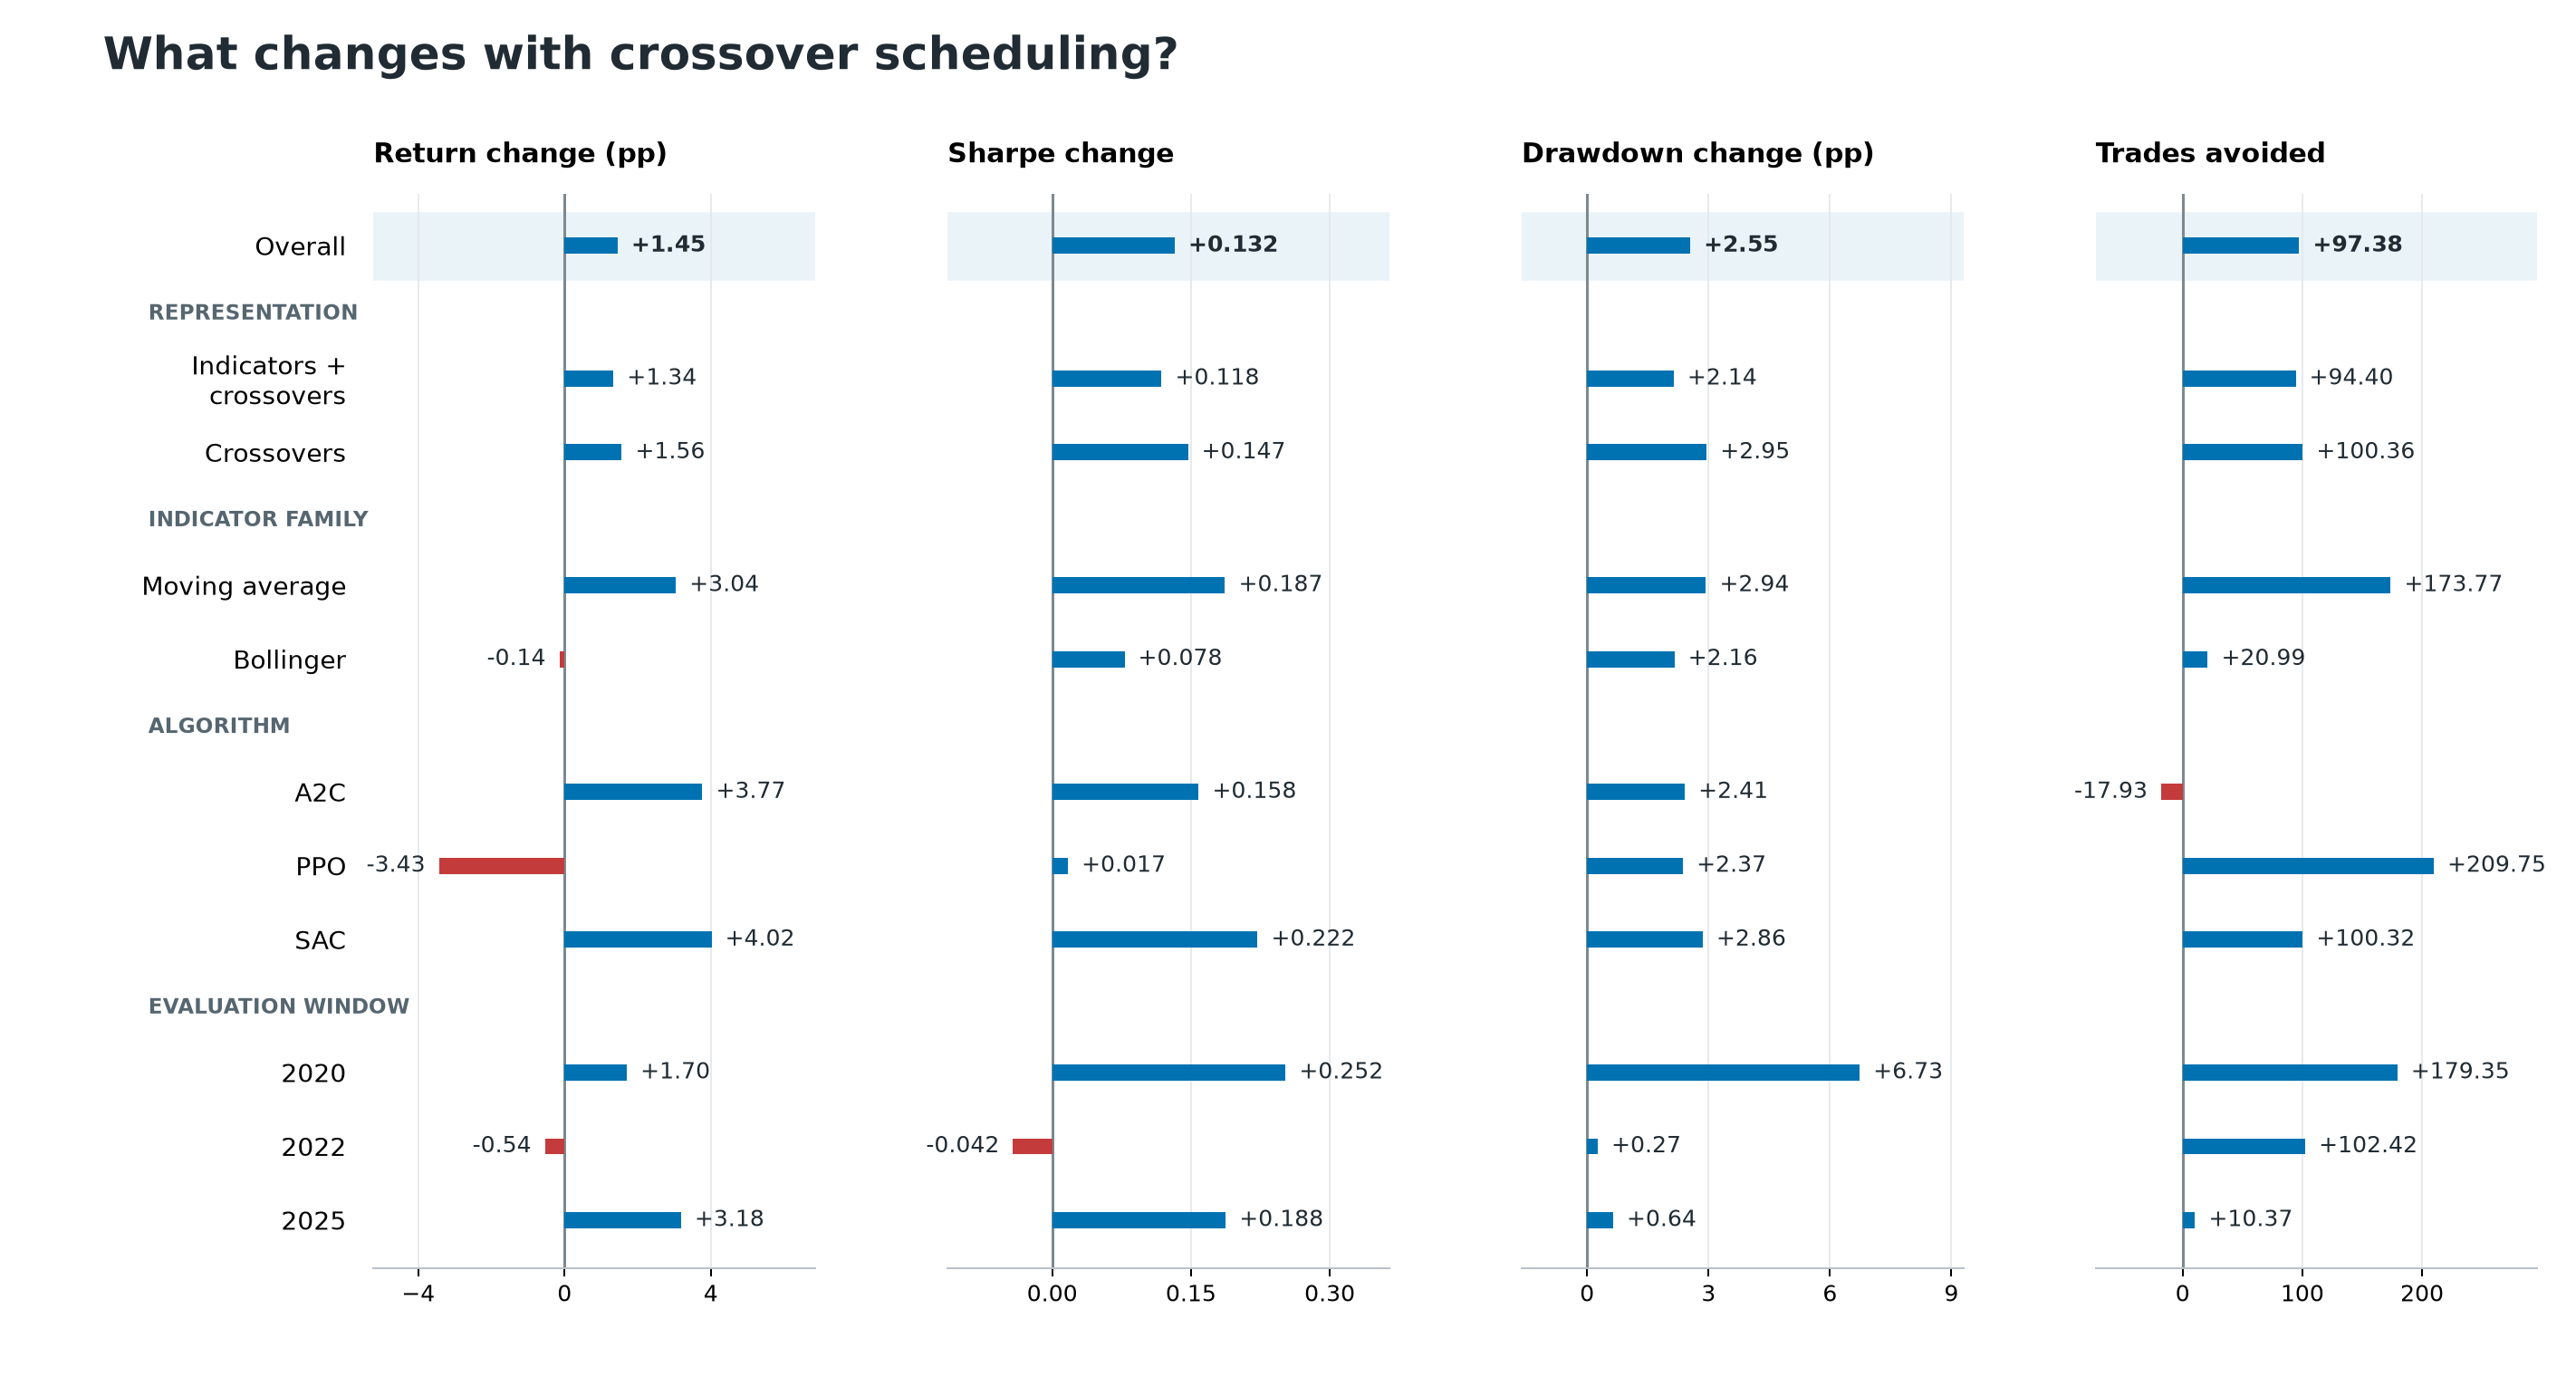

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(descriptive_output / "descriptive_performance.png")))


### Input retention


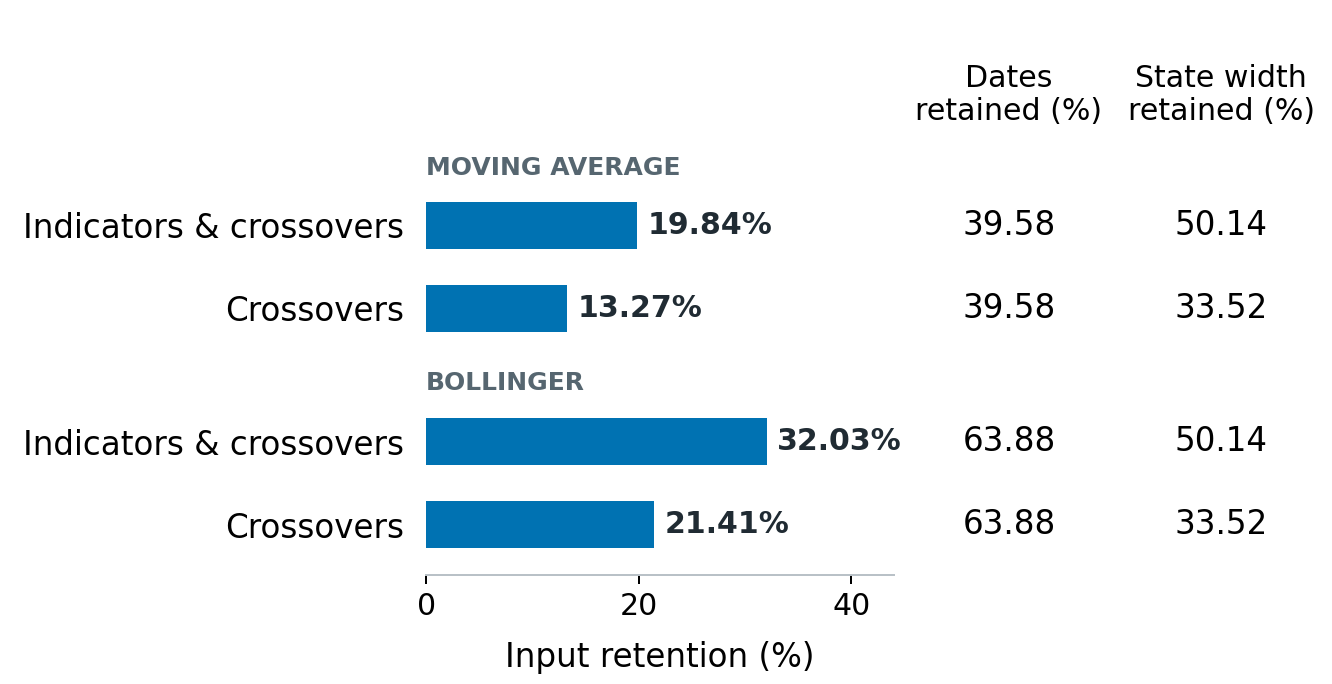

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(descriptive_output / "descriptive_input_retention.png")))


## Random scheduling: seed-paired, shared-schedule-blocked confidence intervals

Run after the descriptive setup cell. Requires SciPy in addition to the plotting dependencies.

Each RR–DD comparison pairs the five outcomes with the same family, window, algorithm and model seed. For a given base indicator family, window and seed, the frozen random schedule is shared by both representations and all three algorithms. The analysis therefore averages the six paired effects within each shared-schedule block and uses the resulting 30 blocks for the pointwise 95% Student-t interval. RR−DD is used for return, Sharpe and signed drawdown; DD−RR is used for trades avoided.

Stars show unadjusted two-sided p-value thresholds (.05/.01/.001). Daggers beneath them show Holm-adjusted thresholds within the named aggregation block. `p_holm_all_44` is an additional broad sensitivity across the displayed 44 tests. The intervals themselves are not multiplicity-adjusted or simultaneous. The three fixed evaluation windows remain the tested grid; block correction does not create new market-window replications.


In [ ]:
import sys, importlib.util
if str(descriptive_root.resolve()) not in sys.path:
    sys.path.insert(0, str(descriptive_root.resolve()))
random_spec = importlib.util.spec_from_file_location("random_schedule_figure", descriptive_root / "random_schedule_figure.py")
random_module = importlib.util.module_from_spec(random_spec)
random_spec.loader.exec_module(random_module)
random_intervals = random_module.generate(descriptive_root / "tables_mv2boll", descriptive_output)


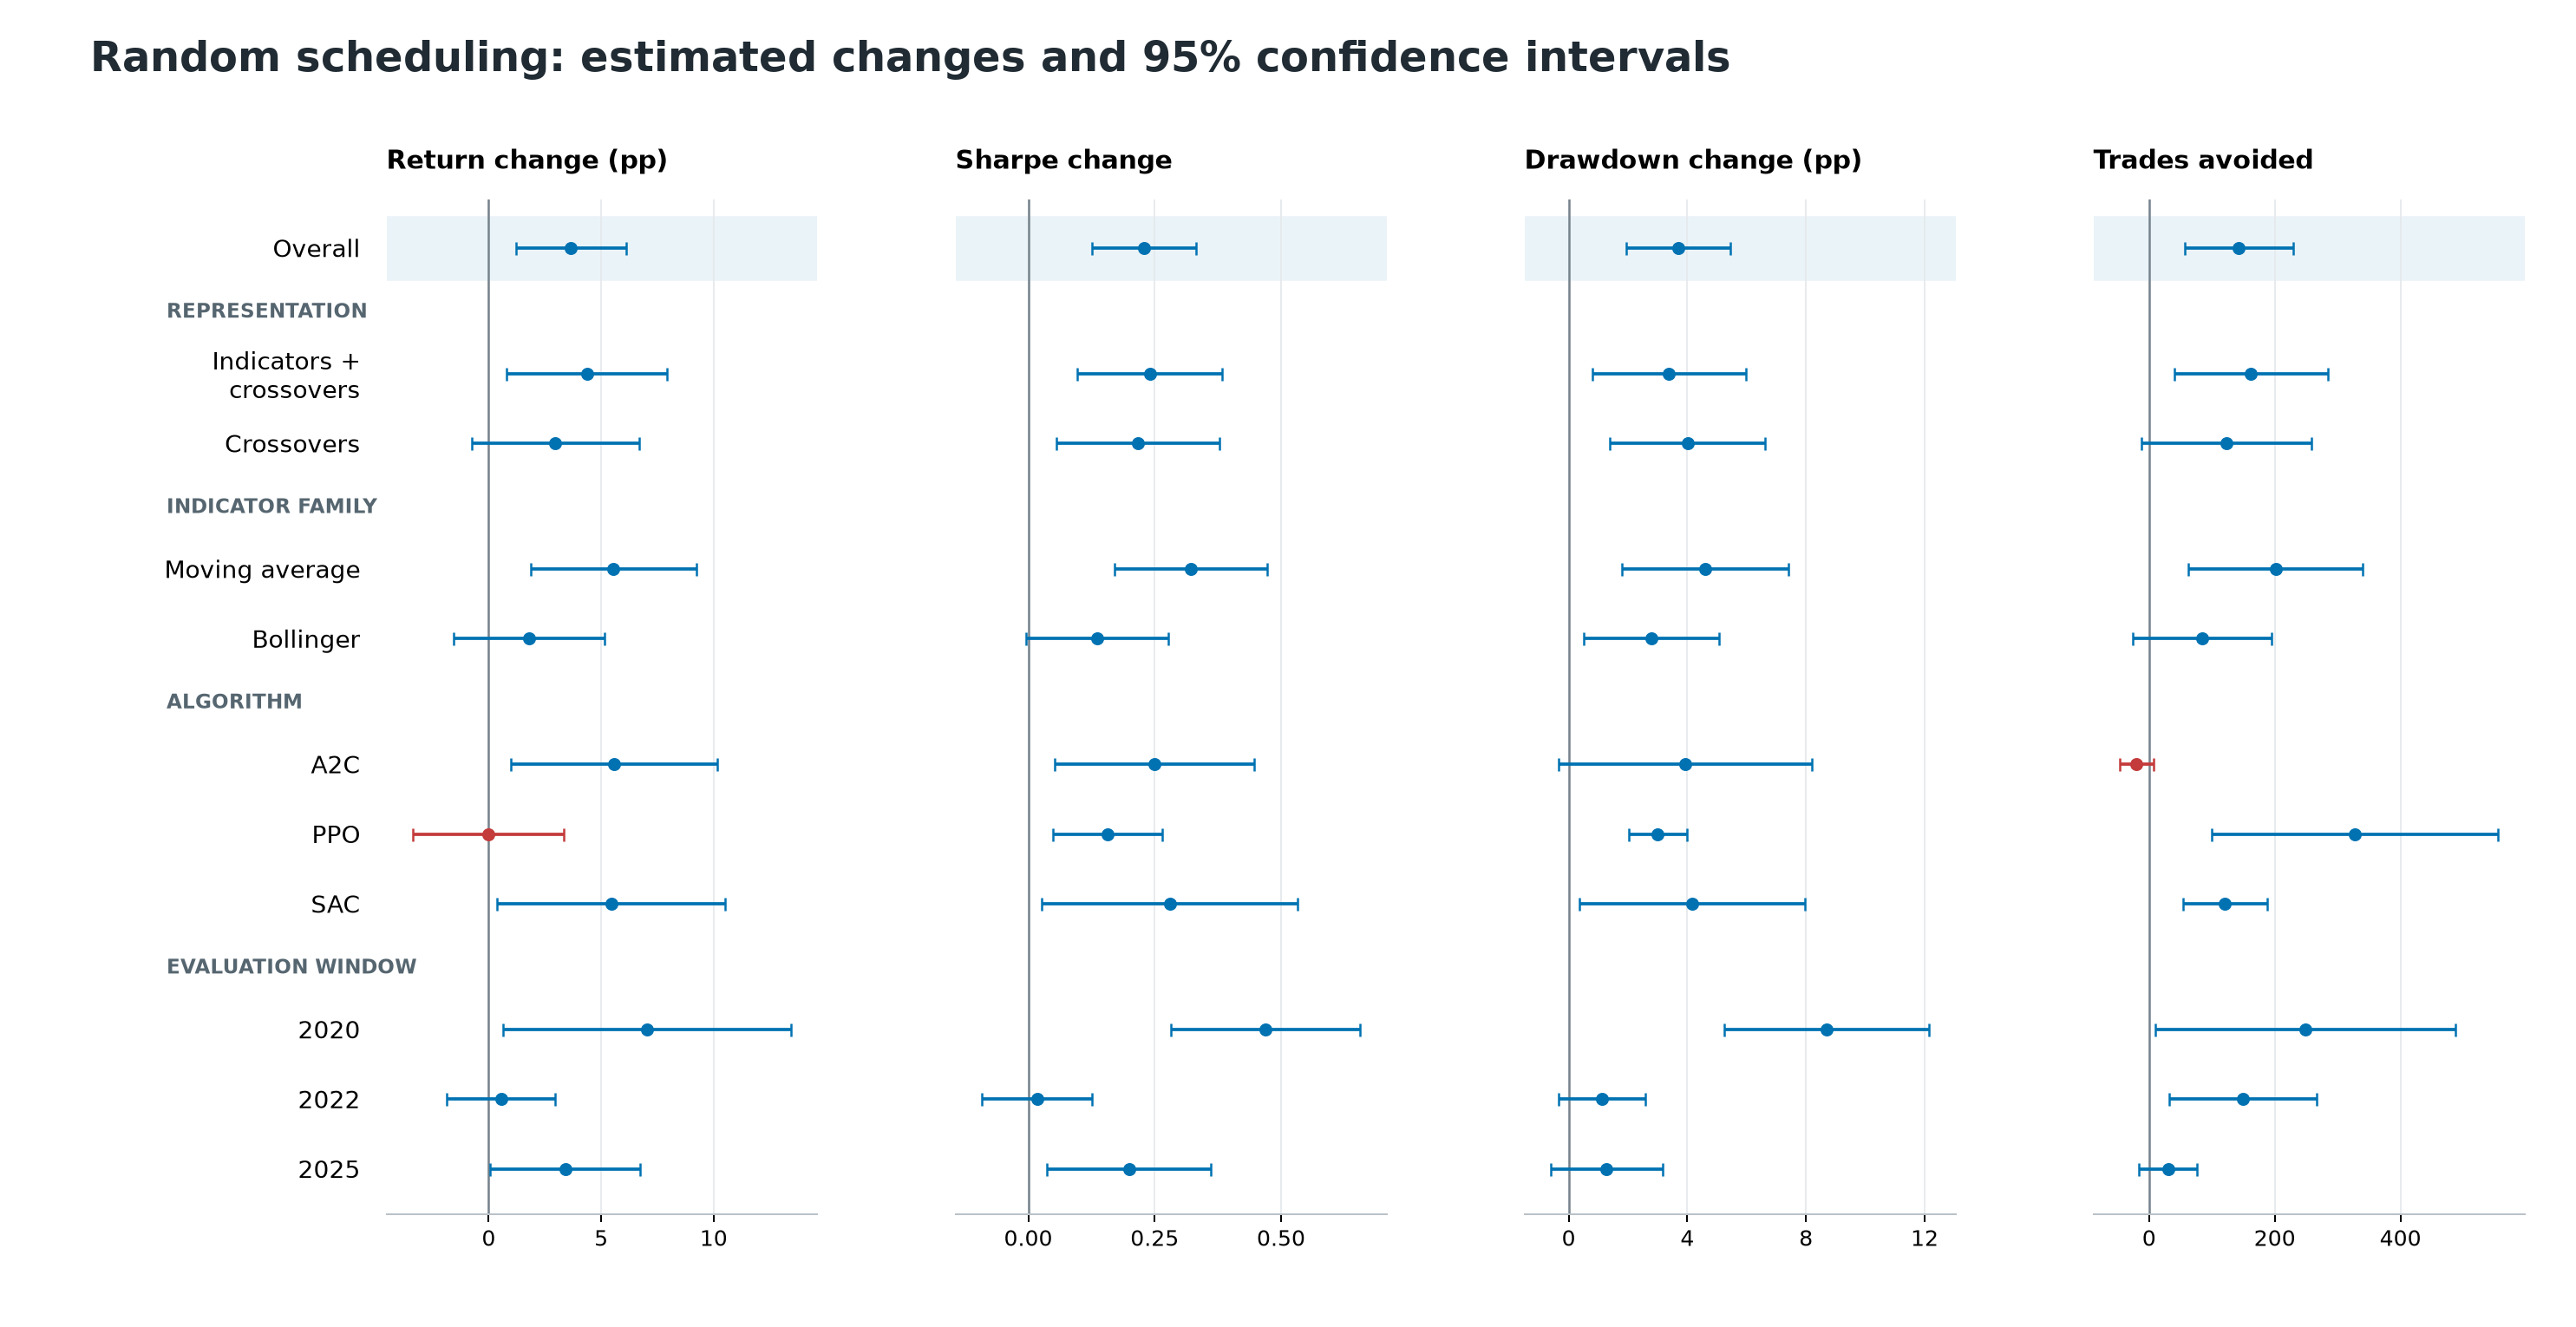

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(descriptive_output / "random_schedule_intervals.png")))


### Diagnostic: the effect of seed pairing and shared-schedule blocking

The three-method chart separates the former configuration-mean calculation from the seed-paired calculations. The second chart isolates the requested comparison: seed-paired results without blocking versus the shared-schedule-blocked result used in the main figure. Point estimates are identical because all methods preserve equal configuration weights; only the uncertainty calculation changes.


In [ ]:
from IPython.display import Image, display
display(Image(filename=str(descriptive_output / "random_schedule_interval_method_comparison.png")))


In [ ]:
from IPython.display import Image, display
display(Image(filename=str(descriptive_output / "random_schedule_interval_seed_block_comparison.png")))


In [ ]:
# Seed-paired blocked results, with raw and Holm-adjusted evidence.
display(random_intervals[["block", "row", "metric", "n_blocks", "n_seed_differences",
                          "estimate", "ci_low", "ci_high", "p", "p_holm",
                          "stars", "daggers", "p_holm_all_44"]].round(5))


## Complementary scheduling effects and fixed-policy controls

Run after the descriptive setup cell. Requires SciPy.

The first four rows answer the 2×2 questions: whether restricting trading helps daily-trained agents; whether scheduled training helps while trading remains daily; whether restricting trading helps schedule-trained agents; and whether scheduled training adds benefits once trading is restricted. The first letter denotes training and the second denotes trading (`D` daily, `E` crossover, `R` random). The last two rows hold a daily-trained indicator baseline or broad RL benchmark fixed, then restrict only its evaluation dates. Those controls have no Crossovers-only counterpart.

All contrasts use actual seed-paired outcomes. For each base family × window × seed, the frozen schedule is shared across two representations and three algorithms; six paired effects are averaged within the block before the test (`n_blocks=30`). Positive return, Sharpe, drawdown and Trades values mean improvement; Trades is expressed as trades avoided. Each cell shows the effect, raw-p stars and Holm daggers beneath. Holm corrects four metrics × two representations within each conceptual question and schedule (eight tests); a fixed-policy control has four metrics in its single applicable representation. `p_holm_all_available` is a broader 80-test sensitivity. The rows are overlapping comparisons, so they are not additive causal components.


In [ ]:
import sys, importlib.util
if str(descriptive_root.resolve()) not in sys.path:
    sys.path.insert(0, str(descriptive_root.resolve()))
effects_spec = importlib.util.spec_from_file_location("scheduling_effects_heatmap", descriptive_root / "scheduling_effects_heatmap.py")
effects_module = importlib.util.module_from_spec(effects_spec)
effects_spec.loader.exec_module(effects_module)
effects_results = effects_module.generate(descriptive_root / "tables_mv2boll", descriptive_output)


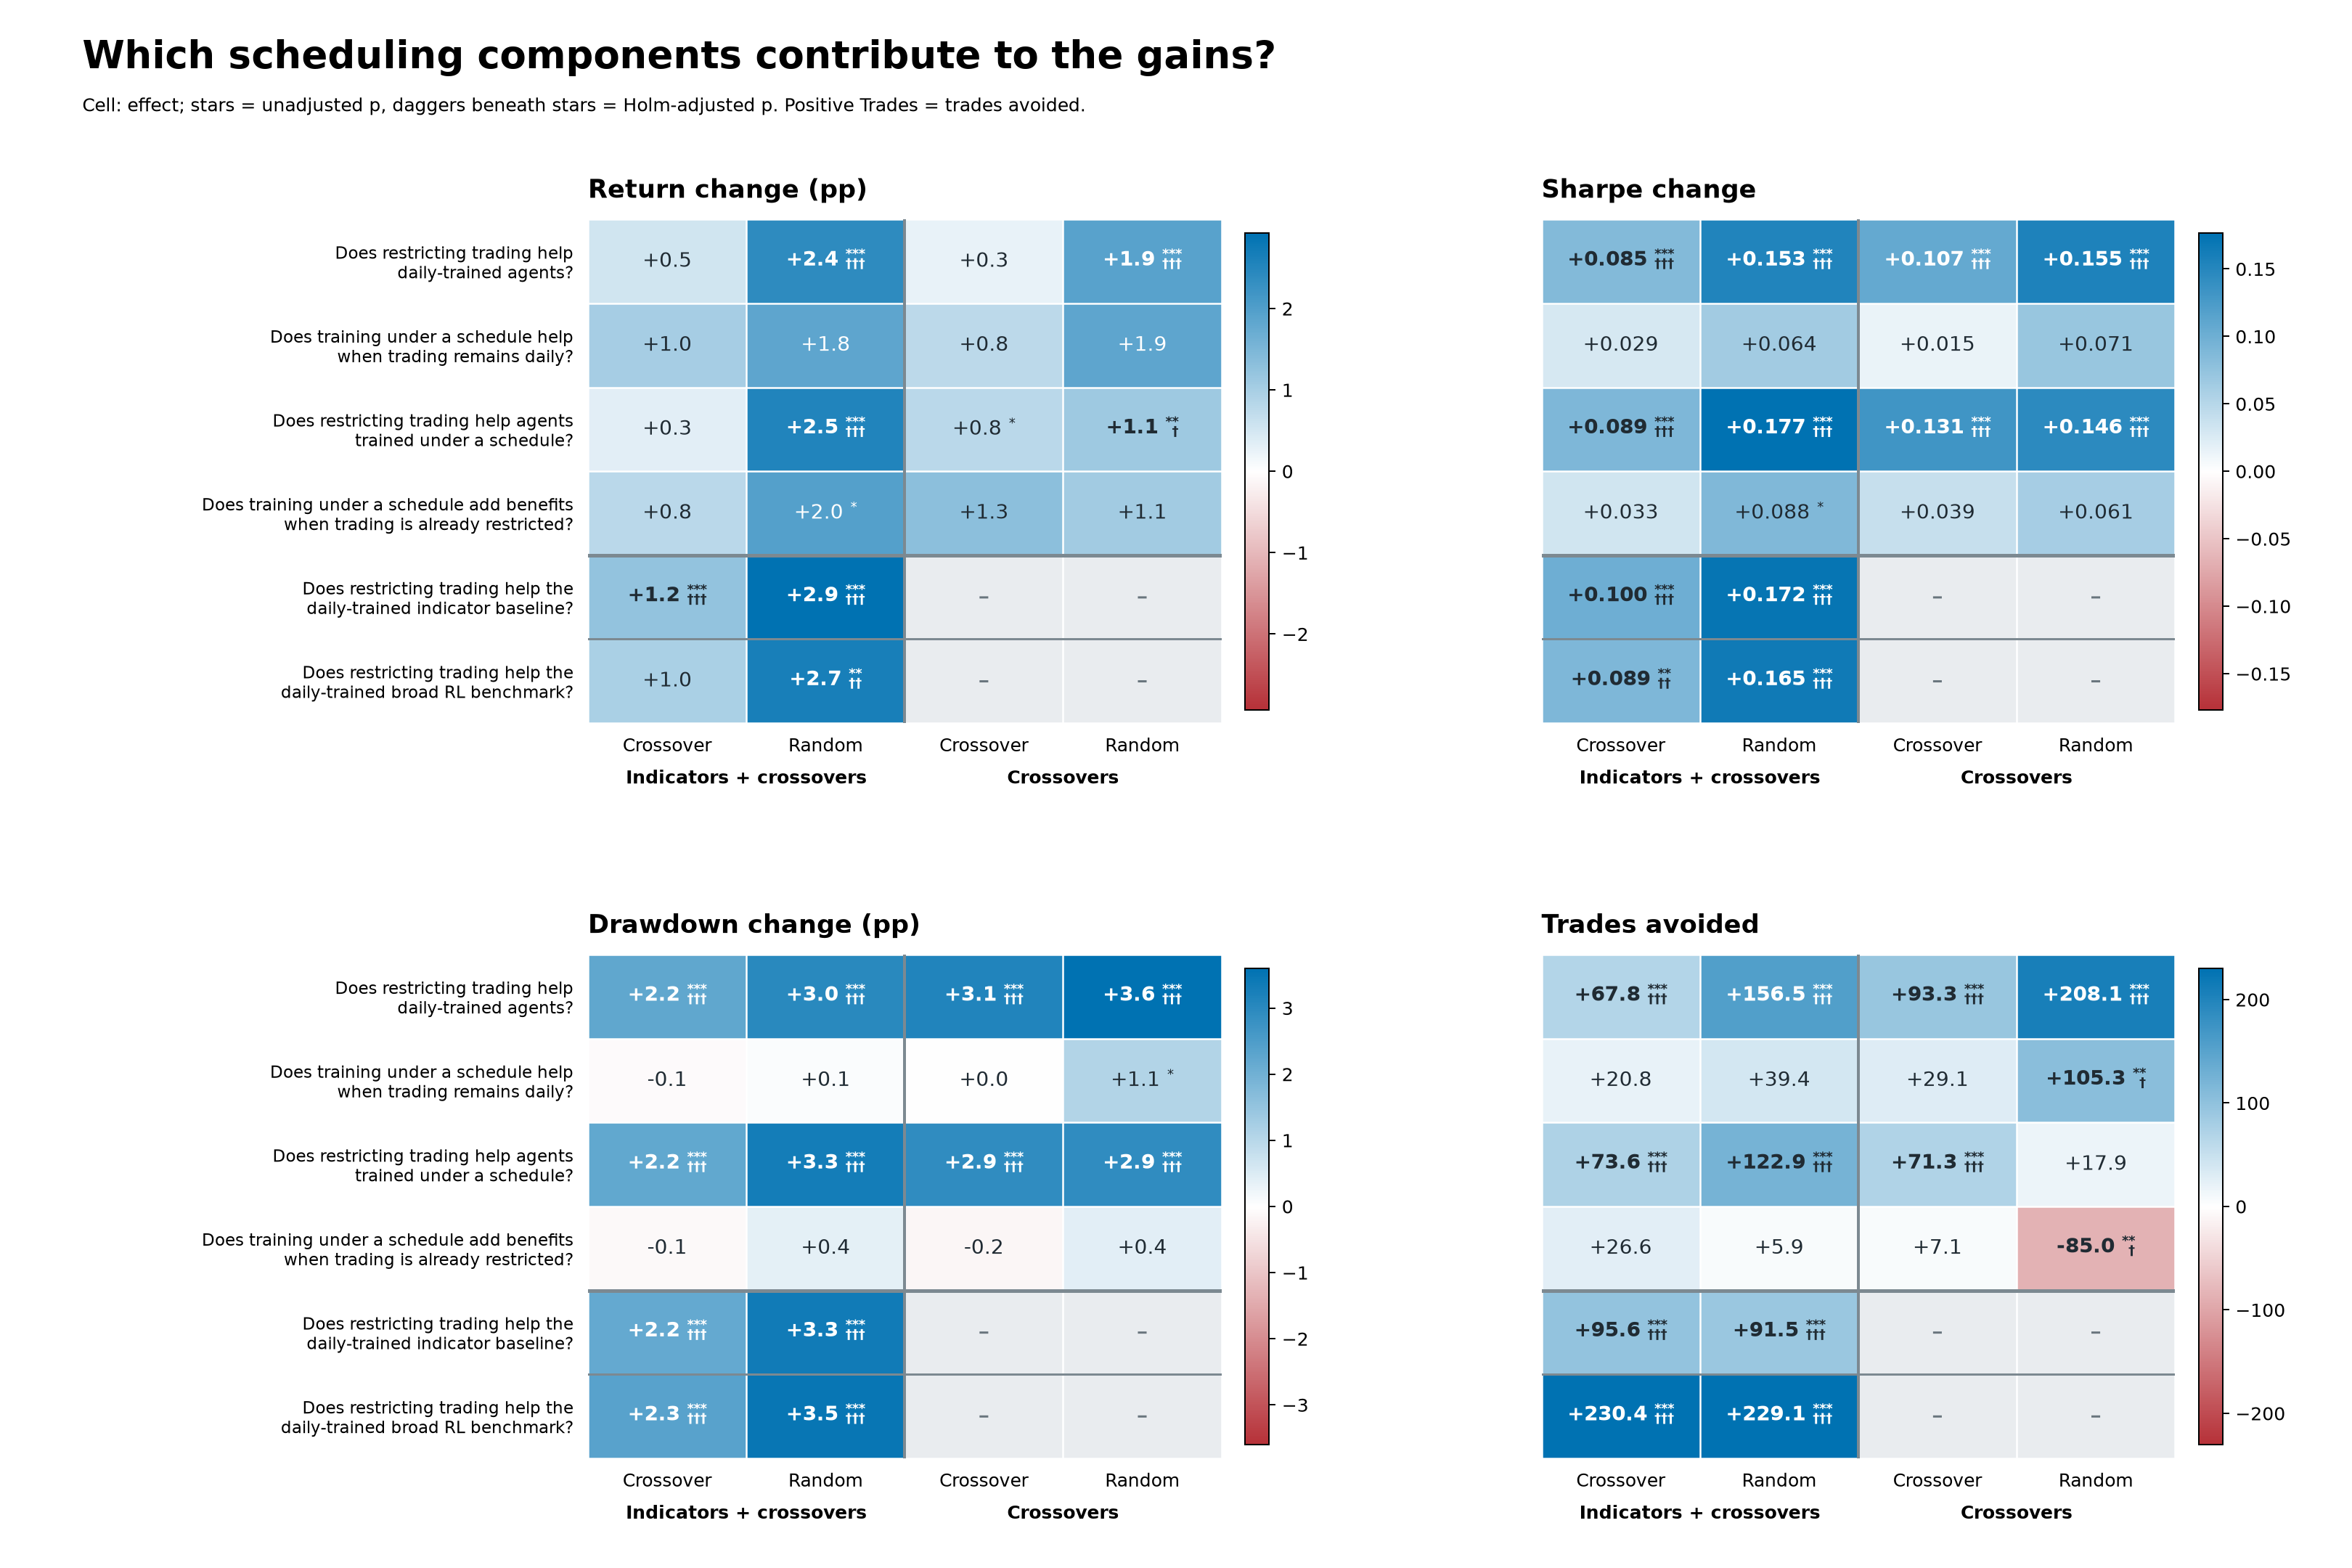

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(descriptive_output / "scheduling_effects_heatmap.png")))


In [ ]:
display(effects_results[["concept", "schedule", "representation", "contrast", "metric",
                         "n_blocks", "n_seed_differences", "estimate", "ci_low", "ci_high",
                         "p", "p_holm_concept", "stars", "daggers",
                         "p_holm_all_available", "status"]].round(5))


## Descriptive comparison with the daily DRL benchmark

Run after the descriptive setup cell. This separately named figure is the descriptive opening; the matched-DD version above remains available.

Descriptive equal-weight differences of per-seed metric means: crossover scheduling minus the broad daily DRL benchmark (dataset all). Trades avoided reverses the subtraction. Algorithm rows use the same algorithm benchmark averaged over three windows; window rows use the same window benchmark averaged over three algorithms. Overall, family and representation rows use the equally weighted benchmark average over all nine algorithm-window cells. These comparisons change representation and scheduling together and do not isolate scheduling or establish significance. The matched-DD figure is preserved separately.


In [ ]:
import sys, importlib.util
if str(descriptive_root.resolve()) not in sys.path:
    sys.path.insert(0, str(descriptive_root.resolve()))
benchmark_spec = importlib.util.spec_from_file_location("descriptive_benchmark_figure", descriptive_root / "descriptive_benchmark_figure.py")
benchmark_module = importlib.util.module_from_spec(benchmark_spec)
benchmark_spec.loader.exec_module(benchmark_module)
benchmark_changes = benchmark_module.generate(descriptive_root / "tables_mv2boll", descriptive_output)


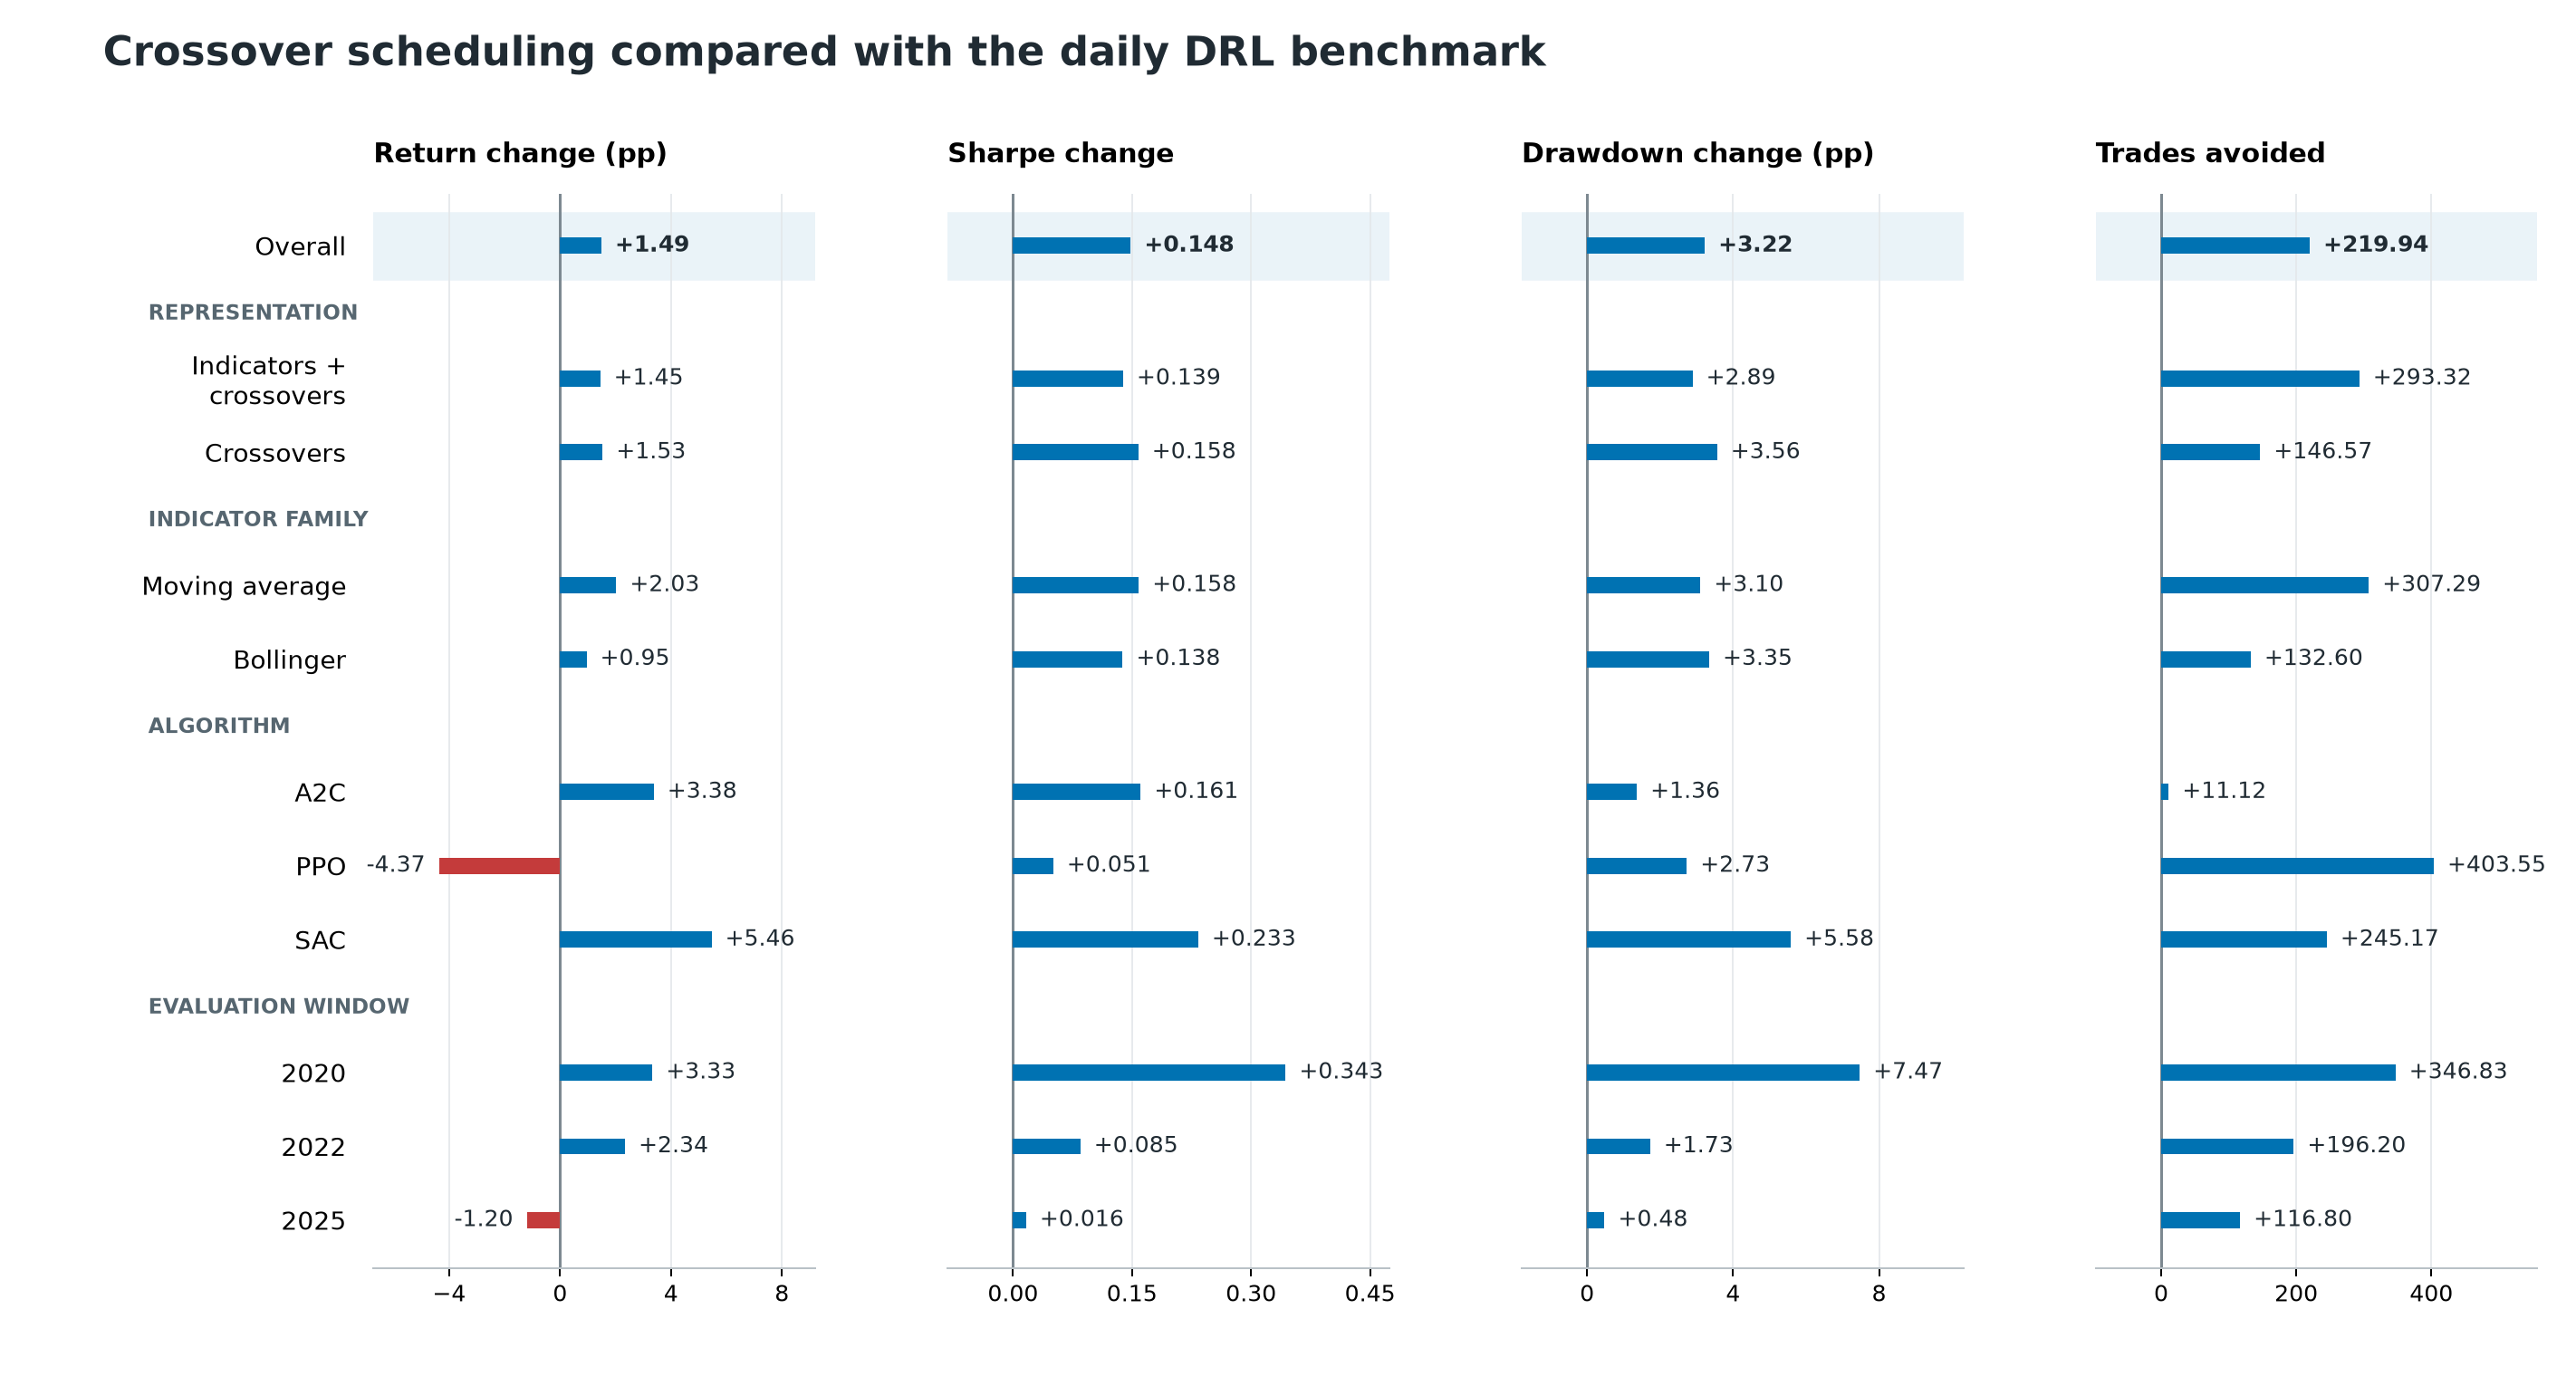

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(descriptive_output / "descriptive_vs_daily_benchmark.png")))
